# Trabalho 3 — GMM com estimação MAP
**Tiago Oliveira Lima — 564988**

In [25]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SEMENTE = 42
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    'figure.figsize': (8, 5),
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.2,
    'figure.dpi': 110,
})

## 1. Carregar e separar os dados

Dados: 150 observações e 2 coordenadas.
Treino: 120 | Validação: 30
Média do treino: [-0.0384 -0.0281]
Desvio-padrão do treino: [1.0141 0.9661]


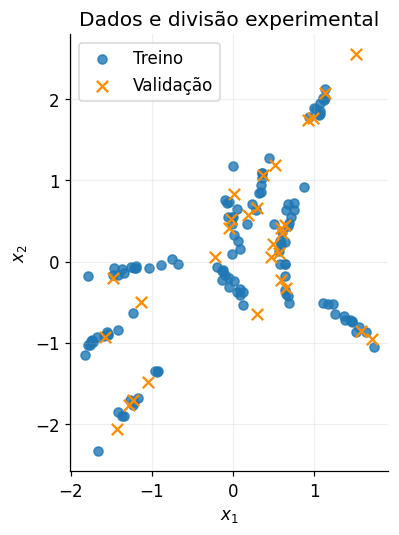

In [26]:
arquivo_dados = Path('clustering_data.csv')

X = np.loadtxt(arquivo_dados, delimiter=',')

N, D = X.shape
indices = np.random.default_rng(SEMENTE).permutation(N)
n_treino = int(0.8 * N)
X_treino = X[indices[:n_treino]]
X_validacao = X[indices[n_treino:]]

media_treino = X_treino.mean(axis=0)
escala_treino = X_treino.std(axis=0, ddof=0)
if np.any(escala_treino == 0):
    raise ValueError('Há uma coordenada constante no treino.')
Z_treino = (X_treino - media_treino) / escala_treino
Z_validacao = (X_validacao - media_treino) / escala_treino

# Correção do jacobiano para avaliar densidades na escala original.
log_jacobiano = np.log(escala_treino).sum()
print(f'Dados: {N} observações e {D} coordenadas.')
print(f'Treino: {len(X_treino)} | Validação: {len(X_validacao)}')
print('Média do treino:', media_treino)
print('Desvio-padrão do treino:', escala_treino)

fig, ax = plt.subplots()
ax.scatter(*X_treino.T, s=35, alpha=0.8, label='Treino')
ax.scatter(*X_validacao.T, s=55, marker='x', color='darkorange', label='Validação')
ax.set(title='Dados e divisão experimental', xlabel='$x_1$', ylabel='$x_2$')
ax.set_aspect('equal', adjustable='box')
ax.legend()
plt.tight_layout()
plt.show()

## 2. Definir o GMM e os priors
* Modelo: $p(z)=\sum_k\pi_k\mathcal N(z\mid\mu_k,\Sigma_k)$, com covariâncias completas. 
* MAP maximiza **log-verossimilhança + log-prior**.
* Dirichlet para os pesos
* Normal–Wishart inversa para médias e covariâncias. 

In [27]:
prior = {
    'alpha': 1.1,
    'm0': np.zeros(D),
    'kappa0': 0.01,
    'nu0': float(D + 2),
    'Psi0': 0.02 * (D + 2 + D + 2) * np.eye(D),
}
print('Hiperparâmetros do prior:')
for nome, valor in prior.items():
    print(f'{nome} = {valor}')

Hiperparâmetros do prior:
alpha = 1.1
m0 = [0. 0.]
kappa0 = 0.01
nu0 = 4.0
Psi0 = [[0.16 0.  ]
 [0.   0.16]]


## 3. Implementar o EM-MAP

In [28]:
def logsumexp(valores, axis=-1, keepdims=False):
    """Log da soma de exponenciais, com subtração do máximo."""
    maior = np.max(valores, axis=axis, keepdims=True)
    resultado = maior + np.log(np.exp(valores - maior).sum(axis=axis, keepdims=True))
    return resultado if keepdims else np.squeeze(resultado, axis=axis)


def log_gaussianas(Z, medias, covariancias):
    """Matriz (N, K): log N(z_n | mu_k, Sigma_k)."""
    n, d = Z.shape
    valores = np.empty((n, len(medias)))
    for k, (mu, cov) in enumerate(zip(medias, covariancias)):
        L = np.linalg.cholesky(cov)
        diferencas = np.linalg.solve(L, (Z - mu).T)
        mahalanobis = np.sum(diferencas**2, axis=0)
        log_det = 2 * np.log(np.diag(L)).sum()
        valores[:, k] = -0.5 * (d * np.log(2 * np.pi) + log_det + mahalanobis)
    return valores


def etapa_e(Z, modelo):
    """Retorna responsabilidades (N, K) e log-densidade de cada ponto."""
    log_conjunta = (log_gaussianas(Z, modelo['medias'], modelo['covariancias'])
                    + np.log(modelo['pesos'])[None, :])
    log_densidade = logsumexp(log_conjunta, axis=1)
    responsabilidades = np.exp(log_conjunta - log_densidade[:, None])
    return responsabilidades, log_densidade

### Atualização MAP



In [ ]:
def etapa_m_map(Z, responsabilidades, prior):
    """Atualiza todos os componentes usando os priors Dirichlet e NIW."""
    n, d = Z.shape
    K = responsabilidades.shape[1]
    Nk = responsabilidades.sum(axis=0)
   
    medias_ponderadas = (responsabilidades.T @ Z) / np.maximum(Nk[:, None], 1e-300)
    kappa = prior['kappa0'] + Nk
    medias = ((prior['kappa0'] * prior['m0'] + Nk[:, None] * medias_ponderadas)
              / kappa[:, None])
    pesos = (Nk + prior['alpha'] - 1) / (n + K * (prior['alpha'] - 1))
    covariancias = np.empty((K, d, d))

    for k in range(K):
        desvios = Z - medias_ponderadas[k]
        dispersao = (desvios.T * responsabilidades[:, k]) @ desvios
        deslocamento = medias_ponderadas[k] - prior['m0']
        Psi = (prior['Psi0'] + dispersao
               + prior['kappa0'] * Nk[k] / kappa[k]
               * np.outer(deslocamento, deslocamento))
        cov = Psi / (prior['nu0'] + Nk[k] + d + 2)
        covariancias[k] = (cov + cov.T) / 2 

    return {'pesos': pesos, 'medias': medias, 'covariancias': covariancias}

### Executar o ajuste
Para cada K, fazemos **8 inicializações** e mantemos a de maior log-posterior no treino. Os centros iniciais são escolhidos de forma espalhada, no estilo k-means++.

O EM para quando a variação relativa do objetivo é pequena ou atinge 500 iterações. A validação não escolhe a inicialização.

In [35]:
def inicializar(Z, K, rng):
    """Escolhe centros espalhados e uma covariância inicial comum."""
    n, d = Z.shape
    medias = np.empty((K, d))
    medias[0] = Z[rng.integers(n)]
    distancias2 = np.sum((Z - medias[0])**2, axis=1)
    for k in range(1, K):
        probabilidades = distancias2 / distancias2.sum()
        medias[k] = Z[rng.choice(n, p=probabilidades)]
        distancias2 = np.minimum(distancias2, np.sum((Z - medias[k])**2, axis=1))
    cov_global = np.cov(Z, rowvar=False, bias=True) + 1e-6 * np.eye(d)
    return {
        'pesos': np.full(K, 1 / K),
        'medias': medias,
        'covariancias': np.repeat(cov_global[None, :, :], K, axis=0),
    }


def log_prior_sem_constantes(modelo, prior):
    """Log-prior usado para comparar iterações/inicializações com o mesmo K."""
    d = modelo['medias'].shape[1]
    valor = (prior['alpha'] - 1) * np.log(modelo['pesos']).sum()
    for mu, cov in zip(modelo['medias'], modelo['covariancias']):
        _, log_det = np.linalg.slogdet(cov)
        deslocamento = mu - prior['m0']
        penalidade_cov = np.trace(np.linalg.solve(cov, prior['Psi0']))
        penalidade_media = prior['kappa0'] * deslocamento @ np.linalg.solve(cov, deslocamento)
        valor -= 0.5 * ((prior['nu0'] + d + 2) * log_det
                        + penalidade_cov + penalidade_media)
    return float(valor)


def ajustar_gmm_map(Z, K, prior, n_inicios=8, max_iter=500, tol=1e-7, semente=42):
    """EM-MAP com múltiplos inícios; retorna o melhor modelo no treino."""
    rng = np.random.default_rng(semente)
    melhor_modelo, melhor_objetivo = None, -np.inf
    objetivos_finais, convergencias = [], []
    for inicio in range(n_inicios):
        modelo = inicializar(Z, K, rng)
        responsabilidades, log_p = etapa_e(Z, modelo)
        historico = [log_p.sum() + log_prior_sem_constantes(modelo, prior)]
        historico_ll = [log_p.sum()]
        convergiu = False
        for _ in range(max_iter):
            modelo = etapa_m_map(Z, responsabilidades, prior)
            responsabilidades, log_p = etapa_e(Z, modelo)
            objetivo = log_p.sum() + log_prior_sem_constantes(modelo, prior)
            historico.append(objetivo)
            historico_ll.append(log_p.sum())
            variacao = historico[-1] - historico[-2]
            if variacao < -1e-7 * (1 + abs(historico[-2])):
                raise RuntimeError('O log-posterior diminuiu além da tolerância numérica.')
            if abs(variacao) <= tol * (1 + abs(historico[-2])):
                convergiu = True
                break
        objetivos_finais.append(historico[-1])
        convergencias.append(convergiu)
        if historico[-1] > melhor_objetivo:
            melhor_objetivo = historico[-1]
            melhor_modelo = {
                **modelo, 'K': K, 'historico': np.array(historico),
                'historico_ll': np.array(historico_ll),
                'n_iter': len(historico) - 1, 'convergiu': convergiu,
                'inicio_escolhido': inicio + 1,
            }
    melhor_modelo['objetivos_inicios'] = np.array(objetivos_finais)
    melhor_modelo['convergencias_inicios'] = np.array(convergencias)
    return melhor_modelo

## 4. Comparar K de 1 a 15

In [36]:
def log_densidade_original(X_novo, modelo):
    Z_novo = (X_novo - media_treino) / escala_treino
    return etapa_e(Z_novo, modelo)[1] - log_jacobiano


Ks = np.arange(1, 16)
modelos = []
for K in Ks:
    modelo = ajustar_gmm_map(Z_treino, int(K), prior, semente=SEMENTE + int(K))
    ll_treino = log_densidade_original(X_treino, modelo).sum()
    ll_validacao = log_densidade_original(X_validacao, modelo).sum()
    q = (K - 1) + K * D + K * D * (D + 1) // 2
    modelo.update({
        'q': int(q), 'll_treino': float(ll_treino),
        'll_validacao': float(ll_validacao),
        'aic': float(2 * q - 2 * ll_treino),
        'bic': float(q * np.log(n_treino) - 2 * ll_treino),
    })
    modelos.append(modelo)

aic = np.array([m['aic'] for m in modelos])
bic = np.array([m['bic'] for m in modelos])
ll_treino = np.array([m['ll_treino'] for m in modelos])
ll_validacao = np.array([m['ll_validacao'] for m in modelos])

print(f"{'K':>2} {'q':>3} {'LL treino':>12} {'LL validação':>13} {'AIC':>11} {'BIC':>11} {'Iter.':>6} {'Conv.':>6}")
for m in modelos:
    print(f"{m['K']:2d} {m['q']:3d} {m['ll_treino']:12.3f} {m['ll_validacao']:13.3f} "
          f"{m['aic']:11.3f} {m['bic']:11.3f} {m['n_iter']:6d} {str(m['convergiu']):>6}")

selecionados = {
    'BIC': modelos[int(np.argmin(bic))],
    'AIC': modelos[int(np.argmin(aic))],
    'Validação': modelos[int(np.argmax(ll_validacao))],
}
print('\nEscolhas (em empates exatos, usamos o menor K):')
for criterio, modelo in selecionados.items():
    print(f"{criterio}: K = {modelo['K']}")

 K   q    LL treino  LL validação         AIC         BIC  Iter.  Conv.
 1   5     -319.710       -81.443     649.421     663.358      2   True
 2  11     -267.931       -71.900     557.863     588.525     47   True
 3  17     -235.034       -61.562     504.068     551.455     24   True
 4  23     -201.938       -63.934     449.877     513.989     26   True
 5  29     -178.702       -57.228     415.403     496.240     23   True
 6  35     -147.233       -59.869     364.467     462.029     19   True
 7  41     -132.526       -64.359     347.052     461.339     35   True
 8  47     -110.244       -58.005     314.488     445.500     39   True
 9  53     -105.593       -58.734     317.186     464.923     58   True
10  59     -102.447       -57.817     322.894     487.356     56   True
11  65     -102.097       -58.670     334.193     515.380     48   True
12  71     -101.231       -58.538     344.462     542.374     49   True
13  77     -101.419       -58.266     356.837     571.474     50

### Gráficos dos critérios

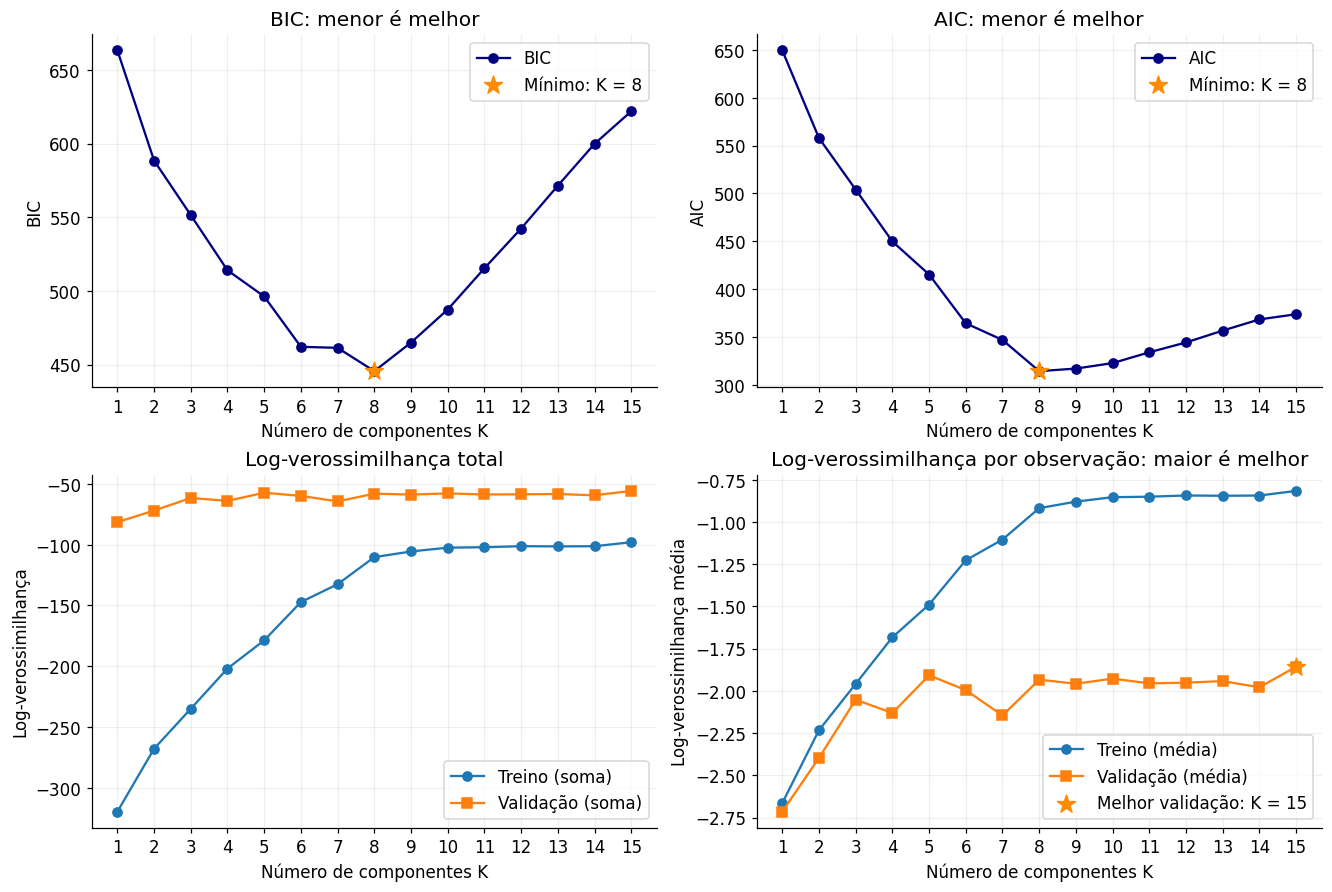

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for ax, valores, nome in [(axes[0, 0], bic, 'BIC'), (axes[0, 1], aic, 'AIC')]:
    indice = int(np.argmin(valores))
    ax.plot(Ks, valores, 'o-', color='navy', label=nome)
    ax.scatter(Ks[indice], valores[indice], s=150, marker='*', color='darkorange',
               zorder=5, label=f'Mínimo: K = {Ks[indice]}')
    ax.set(title=f'{nome}: menor é melhor', ylabel=nome)
    ax.legend()

axes[1, 0].plot(Ks, ll_treino, 'o-', label='Treino (soma)')
axes[1, 0].plot(Ks, ll_validacao, 's-', label='Validação (soma)')
axes[1, 0].set(title='Log-verossimilhança total', ylabel='Log-verossimilhança')
axes[1, 0].legend()

axes[1, 1].plot(Ks, ll_treino / len(X_treino), 'o-', label='Treino (média)')
axes[1, 1].plot(Ks, ll_validacao / len(X_validacao), 's-', label='Validação (média)')
i_val = int(np.argmax(ll_validacao))
axes[1, 1].scatter(Ks[i_val], ll_validacao[i_val] / len(X_validacao),
                   s=150, marker='*', color='darkorange', zorder=5,
                   label=f'Melhor validação: K = {Ks[i_val]}')
axes[1, 1].set(title='Log-verossimilhança por observação: maior é melhor',
               ylabel='Log-verossimilhança média')
axes[1, 1].legend()
for ax in axes.flat:
    ax.set(xlabel='Número de componentes K', xticks=Ks)
plt.show()

## 5. Agrupamentos encontrados

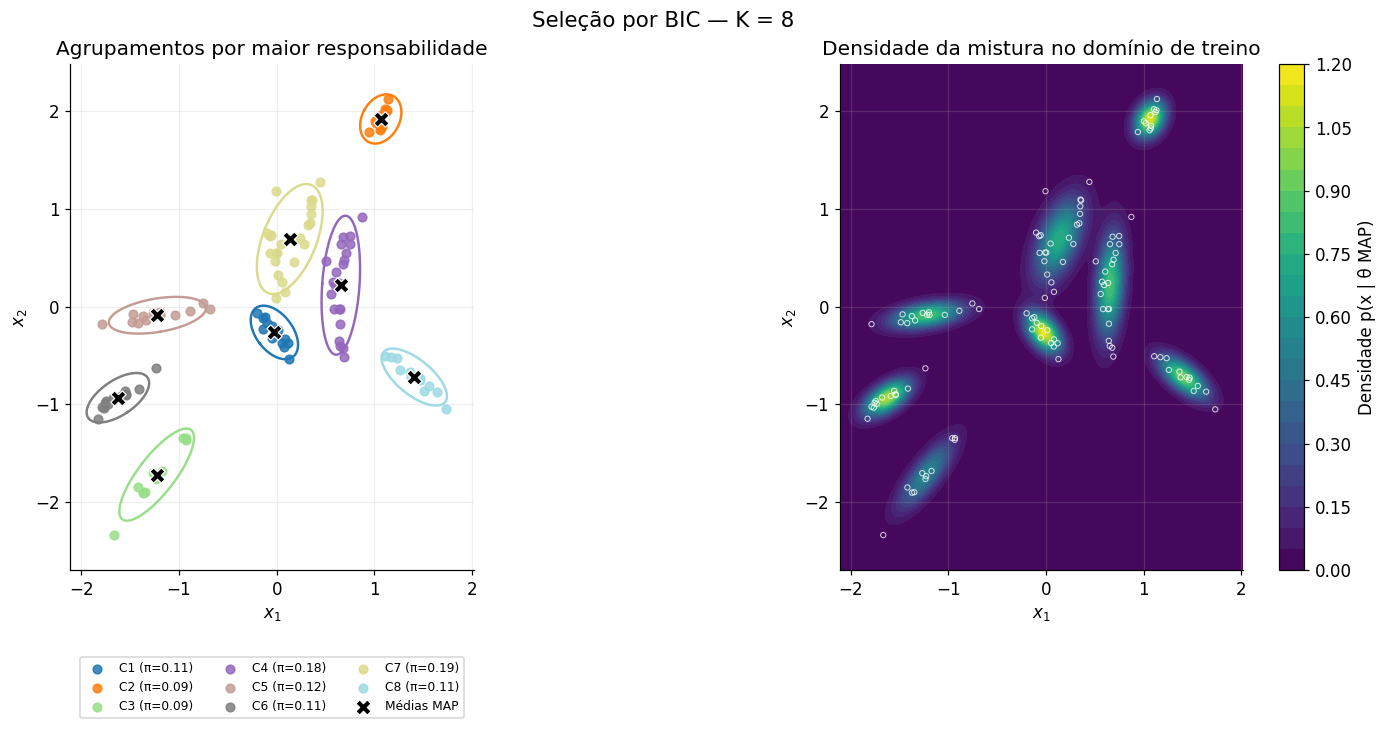

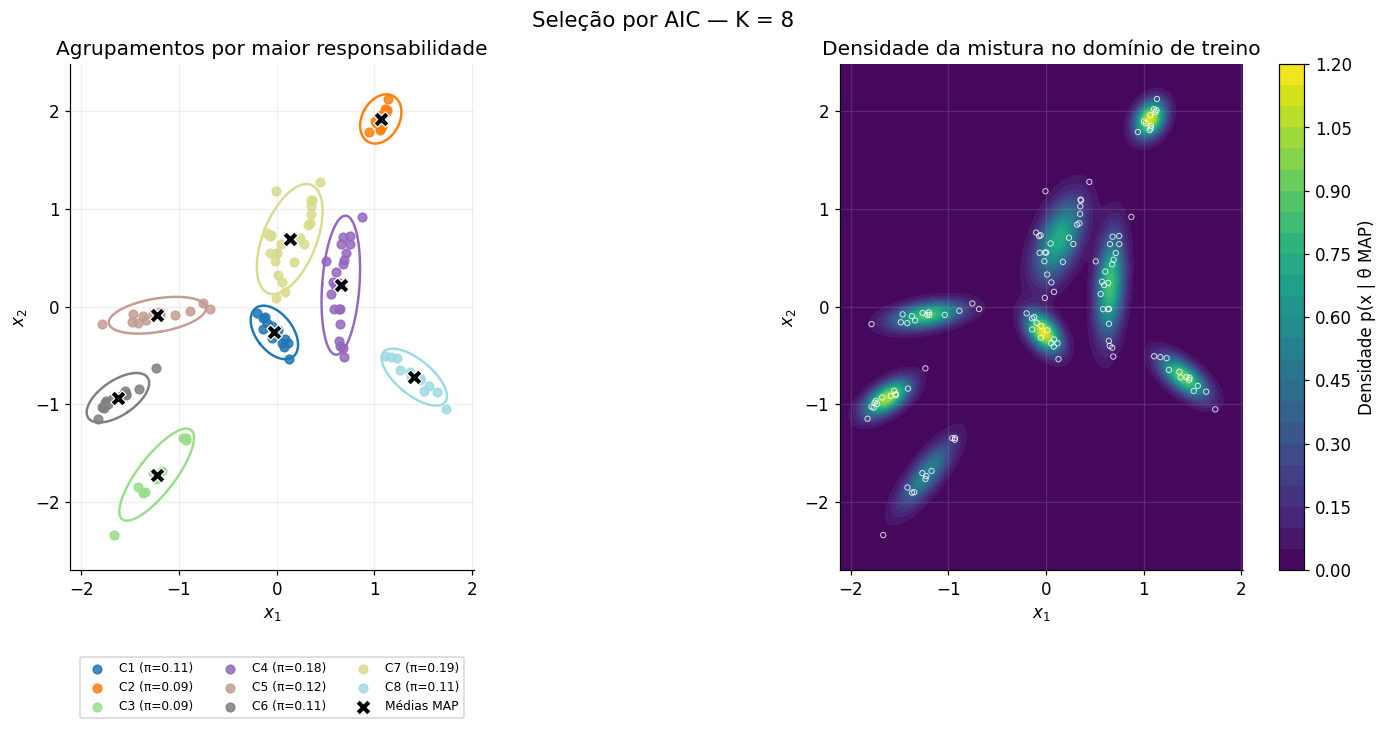

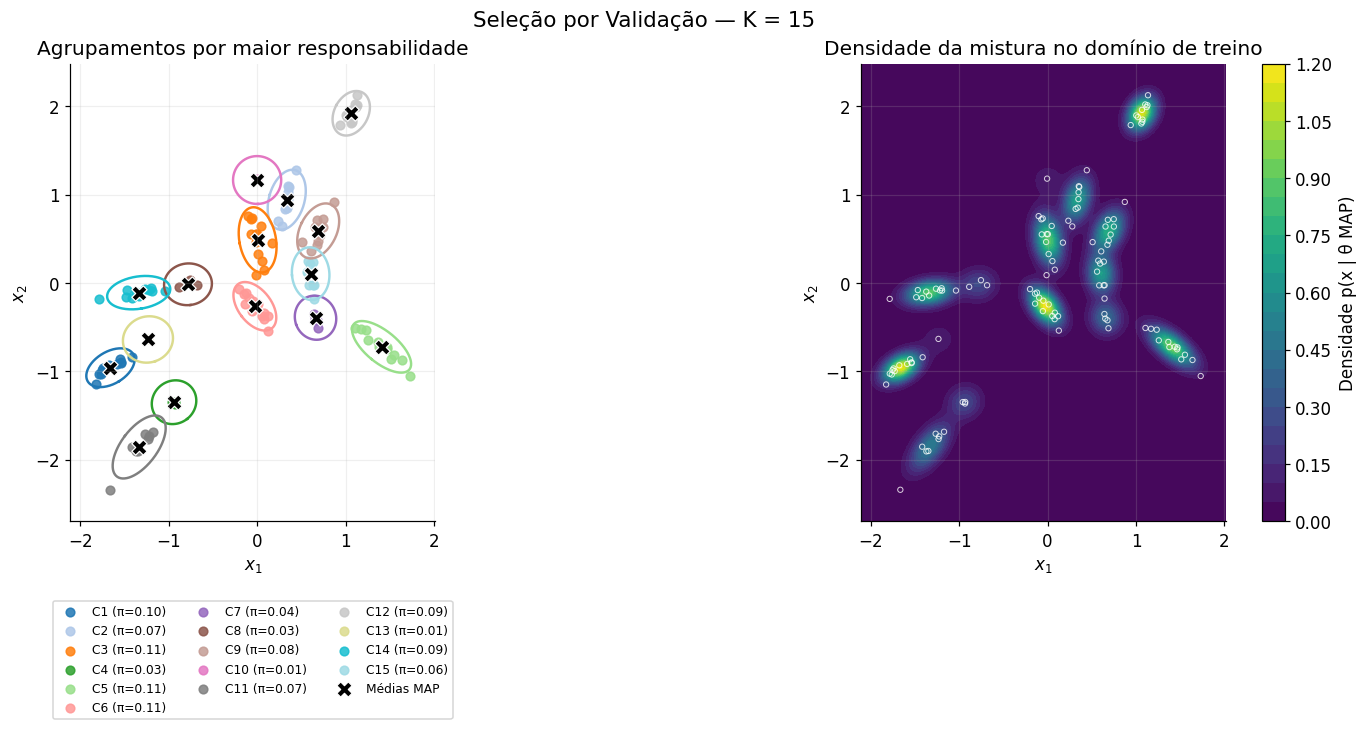

In [37]:
# Malha definida exclusivamente pelo intervalo dos dados de treino.
margem = 0.08 * np.ptp(X_treino, axis=0)
limite_inferior = X_treino.min(axis=0) - margem
limite_superior = X_treino.max(axis=0) + margem
eixo_1 = np.linspace(limite_inferior[0], limite_superior[0], 180)
eixo_2 = np.linspace(limite_inferior[1], limite_superior[1], 180)
G1, G2 = np.meshgrid(eixo_1, eixo_2)
malha = np.column_stack([G1.ravel(), G2.ravel()])


def plotar_modelo(modelo, criterio):
    responsabilidades, _ = etapa_e(Z_treino, modelo)
    grupos = np.argmax(responsabilidades, axis=1)
    medias_originais = modelo['medias'] * escala_treino + media_treino
    cov_originais = (modelo['covariancias']
                     * escala_treino[None, :, None] * escala_treino[None, None, :])
    densidade = np.exp(log_densidade_original(malha, modelo)).reshape(G1.shape)
    cores = plt.get_cmap('tab20')(np.linspace(0, 1, modelo['K']))
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), layout='constrained')

    angulos = np.linspace(0, 2 * np.pi, 200)
    circulo = np.vstack([np.cos(angulos), np.sin(angulos)])
    for k in range(modelo['K']):
        pontos = X_treino[grupos == k]
        axes[0].scatter(*pontos.T, s=32, color=cores[k], alpha=0.85,
                        label=f'C{k + 1} (π={modelo["pesos"][k]:.2f})')
        autovalores, autovetores = np.linalg.eigh(cov_originais[k])
        elipse = medias_originais[k, :, None] + 2 * (
            autovetores @ (np.sqrt(autovalores)[:, None] * circulo))
        axes[0].plot(*elipse, color=cores[k], lw=1.6)
    axes[0].scatter(*medias_originais.T, marker='X', s=100,
                    c='black', edgecolors='white', linewidths=0.8, label='Médias MAP')
    axes[0].set_title('Agrupamentos por maior responsabilidade')
    axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16),
                    ncol=3 if modelo['K'] > 6 else 2)

    superficie = axes[1].contourf(G1, G2, densidade, levels=25, cmap='viridis')
    axes[1].scatter(*X_treino.T, s=12, facecolors='none', edgecolors='white',
                    linewidths=0.65, alpha=0.8)
    axes[1].set_title('Densidade da mistura no domínio de treino')
    fig.colorbar(superficie, ax=axes[1], label='Densidade p(x | θ MAP)')
    for ax in axes:
        ax.set(xlabel='$x_1$', ylabel='$x_2$',
               xlim=(limite_inferior[0], limite_superior[0]),
               ylim=(limite_inferior[1], limite_superior[1]))
        ax.set_aspect('equal', adjustable='box')
    fig.suptitle(f"Seleção por {criterio} — K = {modelo['K']}", fontsize=14)
    plt.show()


for criterio, modelo in selecionados.items():
    plotar_modelo(modelo, criterio)

## 6. Resumo dos resultados

In [39]:
print(f"{'Critério':<12} {'K':>3} {'AIC':>10} {'BIC':>10} {'LL/N treino':>13} {'LL/N valid.':>13}")
for nome, m in selecionados.items():
    print(f"{nome:<12} {m['K']:3d} {m['aic']:10.3f} {m['bic']:10.3f} "
          f"{m['ll_treino'] / len(X_treino):13.4f} {m['ll_validacao'] / len(X_validacao):13.4f}")

if selecionados['Validação']['K'] == Ks[-1]:
    print('\nA validação escolheu K=15, o limite superior do intervalo avaliado.')


Critério       K        AIC        BIC   LL/N treino   LL/N valid.
BIC            8    314.488    445.500       -0.9187       -1.9335
AIC            8    314.488    445.500       -0.9187       -1.9335
Validação     15    373.910    621.997       -0.8163       -1.8569

A validação escolheu K=15, o limite superior do intervalo avaliado.
